# 20. BTC contagion in altcoin early warnings, alert-budget sweep, lead times and capacity use

My conclusion through notebook 19 is that high-risk periods are visible from the previous day's volatility alone, while information on when a crash begins is weak, present only in the last few hours, and much smaller out of sample. Here I check four points that could explain or challenge that conclusion.

- A. Altcoin early warnings as BTC decline detection (stored notebook 17 holdout results for 10 altcoins and the BTC 2018–2019 raw data archived by notebook 11). In 2018 BTC had no early warning (notebook 11) while altcoins had a little (notebook 17); if BTC was already falling when an altcoin alert fired, that warning is detection of a decline that started in another asset. I compare the share of minutes with BTC at least 0.5%, 1% or 2% below its 240-minute trailing high across pre-onset hits, in-progress hits, false alerts and arbitrary minutes (baseline). I also compare pre-onset hit rates between altcoin events that began after BTC had already fallen 1% or more and the other events.
- B. Alert budget (BTC development period 2023-01 to 2026-04): I sweep budgets of 60, 120, 240, 480 and 960 alerts per year (monthly cap 1/12 of the budget) and recalibrate the thresholds on 2022 by the notebook 05 rule at each budget. For each budget I measure excess hits for pre-onset warning and in-progress detection against two nulls (circular shift of at least 7 days, regime-matched).
- C. Lead time: I measure the minutes between matched alerts and the onset of the decline, and how far the price had already fallen at the alert, for the BTC development period (with prices), the BTC 2018–2020 holdout (stored notebook 11 alerts and raw data) and the altcoin holdout (stored alerts, times only).
- D. Capacity use: I tabulate the budget use of the frozen thresholds and budgets by coin and method, and the change in candidate rate relative to 2022.

The budget sweep is exploratory, and every result that uses holdout files is post hoc and descriptive. I do not re-test the hypotheses of notebooks 11 and 17; I work only from their stored alert and event files and the BTC raw data. I write the results to `btc_lead_cost_results_77months_spot/contagion_capacity_leadtime_v1/`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
import joblib
from scipy.stats import fisher_exact

OUT = SPOT_BASE / 'contagion_capacity_leadtime_v1'; OUT.mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
HOLD11 = SPOT_BASE / 'HOLDOUT_2018_2020_confirmatory_v1'; RAW11 = DRIVE / 'BTCUSDT_spot_holdout_2017_2020' / '1m'
HOLD17 = SPOT_BASE / 'HOLDOUT17_multicoin_2018_2019_v1'
DNAME, DCL, ALT_DEF = '4pct', 0.04, 'd4'
METHODS = ['M0_VF_logit', 'M1_vol_threshold', 'M3_GBM_rich']
BUDGETS = [60, 120, 240, 480, 960]
BTC_DD = (0.005, 0.01, 0.02); LED_DD = 0.01
N_NULL = 1000; SEED = 20261103; H11 = ('2018-01-01', '2021-01-01'); H17_END = '2020-01-01'

for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json', HOLD11 / 'HOLDOUT_EVALUATED.lock', HOLD11 / 'HOLDOUT_RESULTS.json',
           HOLD11 / 'holdout_events.csv', HOLD11 / 'alarms_calendar.csv', HOLD11 / 'spot_download_manifest.csv',
           HOLD17 / 'HOLDOUT17_EVALUATED.lock', HOLD17 / 'HOLDOUT17_RESULTS.json', HOLD17 / 'H17_primary_decisions.csv']:
    if not _p.is_file():
        raise FileNotFoundError(f'Required earlier result not found: {_p}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text()); SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256'] or SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: notebook-16 spec/settings differ')

SPEC = {'title': 'BTC contagion in alt early warnings, alert-budget sweep, lead times and capacity use (exploratory / post hoc)',
        'A_contagion': {'data': 'notebook-17 stored alerts and d4 events (10 alts, 2018-2019); BTC 1m from notebook-11 archives (SHA-256 checked)',
                        'btc_state': 'BTC close at the alert minute vs its trailing-240-min high', 'thresholds': BTC_DD, 'btc_led_event': f'BTC >= {LED_DD:.0%} below its trailing high at the alt 1% onset',
                        'status': 'post hoc, descriptive; notebook-17 hypotheses are not re-tested'},
        'B_budget': {'budgets_per_year': BUDGETS, 'monthly_cap': 'budget/12', 'cooldown_min': COOLDOWN, 'calibration': 'notebook-5 rule on 2022 at each budget',
                     'guard': 'budget 240 reproduces notebook-16 thresholds and alarms', 'nulls': f'circular >= 7d and regime-matched, {N_NULL} draws', 'period': f'{EVAL_START}..{EVAL_END}'},
        'C_lead': 'matched alerts: minutes from the 1% onset; decline already realised at the alert (BTC samples only)',
        'D_capacity': 'alerts / calendar capacity (20 per month, 240 per year) and 2022 vs dev candidate rates',
        'seed': SEED, 'notebook16_spec_sha256': FROZEN16['spec_sha256']}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '20_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'20_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/contagion_capacity_leadtime_v1 | spec sha256 394fd96d6658634e


## 1. BTC development period: data, events and scores (notebook 16 frozen models)

In [2]:
t_ = time.time()
px, sg = load_btc_spot()
F = causal_features(px, sg)
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
CAL = VALID & in_period(T, '2022-01-01', '2023-01-01'); EVM = VALID & in_period(T, EVAL_START, EVAL_END); SC = CAL | EVM

TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']
E_ref = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
E = price_only_catalog(close, volume, px.index, decline=DCL)
for c_ in TCOLS:
    E[c_] = pd.to_datetime(E[c_], utc=True)
E = E.sort_values('breach_utc').reset_index(drop=True)
if len(E) != len(E_ref) or any(not np.array_equal(E[c_].astype('int64').to_numpy(), E_ref[c_].astype('int64').to_numpy()) for c_ in TCOLS):
    raise RuntimeError('GUARD FAIL: 4% catalog differs from the notebook-2 catalog')
EV = events_between(E, EVAL_START, EVAL_END)

y_l1 = label_from_catalog(T, E); tr = train_mask(T, VALID)
Xl = F[['z_vol', 'tsr']].to_numpy(float); okl = tr & np.isfinite(Xl).all(axis=1)
cfg0 = FROZEN16['configs'][f'M0_VF_logit|{DNAME}']; m0 = new_logit().fit(Xl[okl], y_l1[okl])
if not (np.allclose(m0[-1].coef_.ravel(), cfg0['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg0['intercept'], rtol=1e-6, atol=1e-9)):
    raise RuntimeError('GUARD FAIL: M0 refit differs from notebook 16')
cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{DNAME}']; mp = SPOT_BASE / cfg3['model_file']
if sha256_file(mp) != cfg3['model_sha256']:
    raise RuntimeError('GUARD FAIL: notebook-16 GBM file SHA-256 differs')
S = {}; IDX = np.flatnonzero(SC)
s = np.full(len(T), np.nan); okp = SC & np.isfinite(Xl).all(axis=1); s[okp] = m0.predict_proba(Xl[okp])[:, 1]; S['M0_VF_logit'] = s
S['M1_vol_threshold'] = np.where(VALID, F.z_vol.to_numpy(float), np.nan)
s = np.full(len(T), np.nan); s[IDX] = joblib.load(mp).predict_proba(F[FEATS].to_numpy(np.float32)[IDX])[:, 1]; S['M3_GBM_rich'] = s
S_VPIN = np.where(VALID, F.vpin.to_numpy(float), np.nan)
_lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
print(f'dev events {len(EV)}; models verified; {time.time() - t_:.0f}s')

dev events 83; models verified; 84s


## B. Pre-onset warning and in-progress detection across alert budgets

M0_VF_logit: budgets done (43s); budget 240 reproduces notebook 16
M1_vol_threshold: budgets done (85s); budget 240 reproduces notebook 16
M3_GBM_rich: budgets done (129s); budget 240 reproduces notebook 16


,method,budget_per_year,dev_alerts,utilization,pre,post,pre_null_regime,post_null_regime,p_pre_regime,p_post_regime,pre_excess_per_100_alerts,post_excess_per_100_alerts,post_share_of_excess
0,M0_VF_logit,60,200,1.000,6,5,1.617,1.018,0.004,0.002,2.192,1.991,0.476
1,M0_VF_logit,120,400,1.000,11,15,3.070,2.136,0.001,0.001,1.982,3.216,0.619
2,M0_VF_logit,240,800,1.000,22,17,5.845,4.054,0.001,0.001,2.019,1.618,0.445
3,M0_VF_logit,480,1600,1.000,24,15,10.682,6.964,0.001,0.003,0.832,0.502,0.376
4,M0_VF_logit,960,3200,1.000,27,31,18.973,11.933,0.020,0.001,0.251,0.596,0.704
5,M1_vol_threshold,60,200,1.000,6,7,1.633,1.021,0.004,0.001,2.184,2.990,0.578
6,M1_vol_threshold,120,400,1.000,9,17,3.069,1.980,0.002,0.001,1.483,3.755,0.717
7,M1_vol_threshold,240,800,1.000,20,18,5.876,4.149,0.001,0.001,1.765,1.731,0.495
8,M1_vol_threshold,480,1600,1.000,29,17,10.684,7.076,0.001,0.001,1.145,0.620,0.351
9,M1_vol_threshold,960,3200,1.000,28,30,19.229,11.855,0.014,0.001,0.274,0.567,0.674


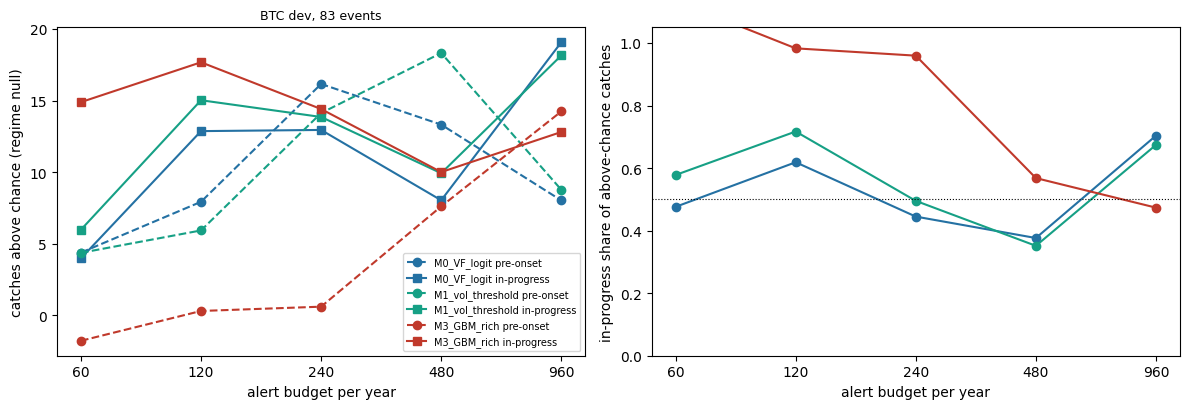

In [3]:
t0_ = ts(EVAL_START).value; L_ = (ts(EVAL_END).value - t0_) // NS
okd = in_period(T, EVAL_START, EVAL_END) & np.isfinite(RV)
TT = T[okd]; DDq = np.minimum((pd.Series(RV[okd]).rank(pct=True).to_numpy() * 10).astype(int), 9)
_order = np.lexsort((TT, DDq)); PP = TT[_order]; DS = DDq[_order]
STARTS = np.searchsorted(DS, np.arange(10), 'left'); ENDS = np.searchsorted(DS, np.arange(10), 'right')


def regime_bounds(a, W=30 * 1440 * NS):
    j = np.clip(np.searchsorted(TT, a, 'right') - 1, 0, len(TT) - 1); ad = DDq[j]
    lo = np.empty(len(a), np.int64); hi = np.empty(len(a), np.int64)
    for q in range(10):
        k = ad == q; seg = PP[STARTS[q]:ENDS[q]]
        lo[k] = STARTS[q] + np.searchsorted(seg, a[k] - W, 'left'); hi[k] = STARTS[q] + np.searchsorted(seg, a[k] + W, 'right')
    return lo, hi


def draw_regime(a, lo, hi, rng):
    c = PP[lo + (rng.random(len(a)) * (hi - lo)).astype(np.int64)]; bad = np.abs(c - a) < LEAD_MAX * NS
    for _ in range(20):
        if not bad.any():
            break
        c[bad] = PP[lo[bad] + (rng.random(int(bad.sum())) * (hi[bad] - lo[bad])).astype(np.int64)]; bad = np.abs(c - a) < LEAD_MAX * NS
    return np.sort(c)


def pre_post(ev, a):
    m = match_events(ev, np.sort(np.asarray(a, np.int64)))
    pre = int(m.pre1pct.sum()) if len(m) else 0
    return pre, len(m) - pre


def capacity(start, end, B, cap):
    mo = pd.period_range(ts(start).tz_localize(None), ts(end).tz_localize(None) - pd.Timedelta(minutes=1), freq='M')
    return int(sum(min(B, cap * n) for n in pd.Series(1, index=mo.year).groupby(level=0).sum()))


bud = []; t_ = time.time()
for mi, mname in enumerate(METHODS):
    s = S[mname]; okc = CAL & np.isfinite(s); oke = EVM & np.isfinite(s); te = T[oke]; se = s[oke]
    for bi, B in enumerate(BUDGETS):
        cap = B // 12
        th, ncal, _ = calibrate_calendar(T[okc], s[okc], B_=B, cap_=cap)
        a = emit_calendar_fast(te, se >= th, B=B, cap=cap)
        if B == 240:
            a16 = np.sort(pd.to_datetime(pd.read_csv(M16 / f'alarms_{mname}_{DNAME}.csv').alarm_utc, utc=True).astype('int64').to_numpy())
            if abs(th - FROZEN16['configs'][f'{mname}|{DNAME}']['threshold_2022']) > 1e-12 or not np.array_equal(a, a16):
                raise RuntimeError(f'GUARD FAIL: budget 240 does not reproduce notebook 16 for {mname}')
        pre, post = pre_post(EV, a); lo, hi = regime_bounds(a)
        rng = np.random.default_rng(SEED + 100 * mi + bi); nc = np.empty((N_NULL, 2)); nr = np.empty((N_NULL, 2))
        for i in range(N_NULL):
            d = int(rng.integers(7 * 1440, L_ - 7 * 1440))
            nc[i] = pre_post(EV, np.sort(t0_ + (a - t0_ + d * NS) % (L_ * NS)))
            nr[i] = pre_post(EV, draw_regime(a, lo, hi, rng))
        capn = capacity(EVAL_START, EVAL_END, B, cap); n = len(a)
        bud.append(dict(method=mname, budget_per_year=B, monthly_cap=cap, threshold_2022=th, cal_alerts_2022=ncal, dev_alerts=n, capacity=capn,
                        utilization=n / capn, events=len(EV), pre=pre, post=post,
                        pre_null_circular=nc[:, 0].mean(), post_null_circular=nc[:, 1].mean(), pre_null_regime=nr[:, 0].mean(), post_null_regime=nr[:, 1].mean(),
                        p_pre_circular=(1 + (nc[:, 0] >= pre).sum()) / (N_NULL + 1), p_pre_regime=(1 + (nr[:, 0] >= pre).sum()) / (N_NULL + 1),
                        p_post_circular=(1 + (nc[:, 1] >= post).sum()) / (N_NULL + 1), p_post_regime=(1 + (nr[:, 1] >= post).sum()) / (N_NULL + 1),
                        pre_excess_per_100_alerts=100 * (pre - nr[:, 0].mean()) / max(n, 1), post_excess_per_100_alerts=100 * (post - nr[:, 1].mean()) / max(n, 1),
                        pre_excess_events=pre - nr[:, 0].mean(), post_excess_events=post - nr[:, 1].mean(),
                        post_share_of_excess=(post - nr[:, 1].mean()) / ((pre + post) - nr.sum(axis=1).mean()) if (pre + post) - nr.sum(axis=1).mean() > 0 else np.nan))
    print(f'{mname}: budgets done ({time.time() - t_:.0f}s); budget 240 reproduces notebook 16', flush=True)
BU = pd.DataFrame(bud); BU.to_csv(OUT / '1_budget_sweep.csv', index=False)
display(BU[['method', 'budget_per_year', 'dev_alerts', 'utilization', 'pre', 'post', 'pre_null_regime', 'post_null_regime', 'p_pre_regime', 'p_post_regime',
            'pre_excess_per_100_alerts', 'post_excess_per_100_alerts', 'post_share_of_excess']].round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
colors = {'M0_VF_logit': '#2471a3', 'M1_vol_threshold': '#16a085', 'M3_GBM_rich': '#c0392b'}
for mname in METHODS:
    g = BU[BU.method == mname]
    ax[0].plot(g.budget_per_year, g.pre_excess_events, marker='o', ls='--', color=colors[mname], label=f'{mname} pre-onset')
    ax[0].plot(g.budget_per_year, g.post_excess_events, marker='s', color=colors[mname], label=f'{mname} in-progress')
    ax[1].plot(g.budget_per_year, g.post_share_of_excess, marker='o', color=colors[mname], label=mname)
for a_ in ax:
    a_.set_xscale('log', base=2); a_.set_xticks(BUDGETS); a_.set_xticklabels(BUDGETS); a_.set_xlabel('alert budget per year')
ax[0].set_ylabel('catches above chance (regime null)'); ax[0].set_title(f'BTC dev, {len(EV)} events', fontsize=9); ax[0].legend(fontsize=7)
ax[1].set_ylabel('in-progress share of above-chance catches'); ax[1].axhline(0.5, color='k', lw=0.8, ls=':'); ax[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.savefig(OUT / '1_budget_sweep.png', dpi=140); plt.show()

## 2. Stored holdout results (hypotheses not re-tested)

In [4]:
t_ = time.time()
H1 = json.loads((HOLD11 / 'HOLDOUT_RESULTS.json').read_text())['H1']
hev = pd.read_csv(HOLD11 / 'holdout_events.csv')
for c_ in TCOLS:
    hev[c_] = pd.to_datetime(hev[c_], utc=True)
hev = hev.sort_values('breach_utc').reset_index(drop=True)
h_al = np.sort(pd.to_datetime(pd.read_csv(HOLD11 / 'alarms_calendar.csv').alarm_utc, utc=True).astype('int64').to_numpy())
sth = statistics(hev, h_al)
if [sth['alarms'], sth['caught'], sth['before_1pct']] != [H1['alarms'], H1['any_hits'], H1['pre_onset_hits']]:
    raise RuntimeError('GUARD FAIL: stored notebook-11 alerts/events do not reproduce H1')
man = pd.read_csv(HOLD11 / 'spot_download_manifest.csv')
for r in man.itertuples():
    if r.status != 'not_listed' and sha256_file(RAW11 / f'{r.symbol}-1m-{r.month}.zip') != r.sha256:
        raise RuntimeError(f'GUARD FAIL: BTC holdout archive {r.month} SHA-256 differs from the notebook-11 manifest')
Hh = regularize(load_archives(man, RAW11), end=pd.Timestamp('2020-12-31 23:59', tz='UTC')).loc[:pd.Timestamp('2020-12-31 23:59', tz='UTC')]
HT = Hh.index.asi8; Hc = Hh.close.to_numpy(float)
_hc = pd.Series(np.where(np.isfinite(Hc) & (Hc > 0), Hc, np.nan))
BTC_DDS = (1 - _hc / _hc.rolling(240, min_periods=120).max()).to_numpy()
BTC_R60 = np.log(_hc).diff(60).to_numpy()


def at(times, grid, arr):
    i = np.searchsorted(grid, times, 'left'); ok = (i < len(grid)) & (grid[np.minimum(i, len(grid) - 1)] == times)
    out = np.full(len(times), np.nan); out[ok] = arr[i[ok]]; return out


res17 = json.loads((HOLD17 / 'HOLDOUT17_RESULTS.json').read_text()); COINS = res17['coins_evaluated']
dec17 = pd.read_csv(HOLD17 / 'H17_primary_decisions.csv').set_index('method')
ALT = {}
for sym in COINS:
    meta = json.loads((HOLD17 / 'phase2' / f'{sym}_meta.json').read_text())
    if meta.get('excluded'):
        continue
    z = np.load(HOLD17 / 'phase2' / f'{sym}.npz'); e = pd.read_csv(HOLD17 / 'phase2' / f'{sym}_{ALT_DEF}_events.csv')
    for c_ in TCOLS:
        e[c_] = pd.to_datetime(e[c_], utc=True)
    ALT[sym] = dict(meta=meta, ev=e.sort_values('breach_utc').reset_index(drop=True), A={k[2:]: z[k] for k in z.files if k.startswith('A|')})
for mname in METHODS:
    pp = np.sum([pre_post(d['ev'], d['A'][f'{mname}|{ALT_DEF}']) for d in ALT.values()], axis=0)
    if mname in dec17.index and (int(pp[0]), int(pp[1])) != (int(dec17.loc[mname, 'pre']), int(dec17.loc[mname, 'post'])):
        raise RuntimeError(f'GUARD FAIL: stored notebook-17 alerts do not reproduce the locked counts for {mname}')
print(f'PASS: notebook-11 H1 and notebook-17 primary counts reproduced from stored files; BTC archives verified ({time.time() - t_:.0f}s)')

PASS: notebook-11 H1 and notebook-17 primary counts reproduced from stored files; BTC archives verified (43s)


## A. Was BTC already falling when altcoin alerts fired? (post hoc, descriptive)

method,M0_VF_logit,M1_vol_threshold,M3_GBM_rich
category,,,
any minute (baseline),0.262,0.262,0.262
false alarm,0.450,0.456,0.356
in-progress hit,0.770,0.811,0.690
pre-onset hit,0.313,0.380,0.314


,method,endpoint,btc_led_events,btc_led_hits,btc_led_rate,other_events,other_hits,other_rate,odds_ratio,fisher_p_two_sided_exploratory,share_of_hits_in_btc_led_events,share_of_events_btc_led
0,M0_VF_logit,pre,403,39,0.097,540,28,0.052,1.959,0.010,0.582,0.427
1,M0_VF_logit,post,385,57,0.148,504,82,0.163,0.894,0.577,0.410,0.433
2,M1_vol_threshold,pre,403,41,0.102,540,30,0.056,1.925,0.009,0.577,0.427
3,M1_vol_threshold,post,385,57,0.148,504,86,0.171,0.845,0.407,0.399,0.433
4,M3_GBM_rich,pre,403,18,0.045,540,17,0.031,1.438,0.301,0.514,0.427
5,M3_GBM_rich,post,385,23,0.060,504,48,0.095,0.604,0.061,0.324,0.433


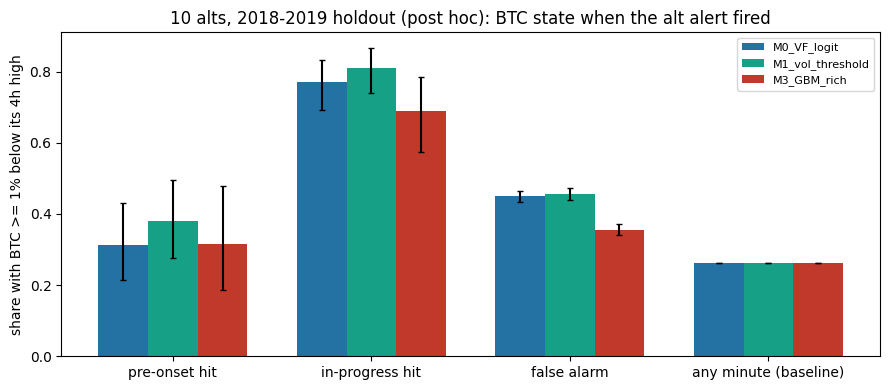

In [5]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


arows = []; erows = []; base = {x: [0, 0] for x in BTC_DD}
for sym, d in ALT.items():
    t0c = ts(d['meta']['eval_start']).value; k = (HT >= t0c) & (HT < ts(H17_END).value) & np.isfinite(BTC_DDS)
    for x in BTC_DD:
        base[x][0] += int((BTC_DDS[k] >= x).sum()); base[x][1] += int(k.sum())
cat_dd = {m: {c: [] for c in ['pre-onset hit', 'in-progress hit', 'false alarm']} for m in METHODS}; cat_r60 = {m: {c: [] for c in cat_dd[m]} for m in METHODS}
for mname in METHODS:
    for sym, d in ALT.items():
        a = np.sort(d['A'][f'{mname}|{ALT_DEF}']); ev = d['ev']; m = match_events(ev, a)
        hit_t = m.alarm_utc.astype('int64').to_numpy() if len(m) else np.array([], np.int64)
        pre_t = hit_t[m.pre1pct.to_numpy()] if len(m) else hit_t; post_t = hit_t[~m.pre1pct.to_numpy()] if len(m) else hit_t
        fa_t = np.setdiff1d(a, hit_t)
        for c, tt in [('pre-onset hit', pre_t), ('in-progress hit', post_t), ('false alarm', fa_t)]:
            cat_dd[mname][c].append(at(tt, HT, BTC_DDS)); cat_r60[mname][c].append(at(tt, HT, BTC_R60))
        on = ev.onset_1pct_utc.astype('int64').to_numpy(); led = at(on, HT, BTC_DDS) >= LED_DD
        pre_ids = set(m.loc[m.pre1pct, 'event_id']) if len(m) else set(); post_ids = set(m.loc[~m.pre1pct, 'event_id']) if len(m) else set()
        gap = (ev.breach_utc - ev.onset_1pct_utc).dt.total_seconds().to_numpy() / 60
        for j, eid in enumerate(ev.event_id):
            erows.append(dict(method=mname, coin=sym, event_id=int(eid), btc_led=bool(led[j]), btc_dd_at_onset=float(at(on[j:j + 1], HT, BTC_DDS)[0]),
                              pre_eligible=bool(gap[j] < LEAD_MAX), post_eligible=bool(gap[j] >= LEAD_MIN), pre_hit=int(eid) in pre_ids, post_hit=int(eid) in post_ids))
for mname in METHODS:
    for c in cat_dd[mname]:
        v = np.concatenate(cat_dd[mname][c]); v = v[np.isfinite(v)]; r = np.concatenate(cat_r60[mname][c]); r = r[np.isfinite(r)]
        for x in BTC_DD:
            kx = int((v >= x).sum()); lo, hi = wilson(kx, len(v))
            arows.append(dict(method=mname, category=c, alerts=len(v), btc_down_threshold=x, share_btc_down=kx / len(v) if len(v) else np.nan,
                              ci_lo=lo, ci_hi=hi, median_btc_dd=float(np.median(v)) if len(v) else np.nan, median_btc_ret60=float(np.median(r)) if len(r) else np.nan))
    for x in BTC_DD:
        arows.append(dict(method=mname, category='any minute (baseline)', alerts=base[x][1], btc_down_threshold=x, share_btc_down=base[x][0] / base[x][1],
                          ci_lo=np.nan, ci_hi=np.nan, median_btc_dd=np.nan, median_btc_ret60=np.nan))
AC = pd.DataFrame(arows); AC.to_csv(OUT / '2_contagion_alert_state.csv', index=False)
display(AC[AC.btc_down_threshold == LED_DD].pivot(index='category', columns='method', values='share_btc_down').round(3))

ER = pd.DataFrame(erows); ER.to_csv(OUT / '2_contagion_events.csv', index=False); led_rows = []
for mname in METHODS:
    g = ER[ER.method == mname]
    for ep, elig in [('pre', 'pre_eligible'), ('post', 'post_eligible')]:
        h = g[g[elig]]; a1 = h[h.btc_led]; a0 = h[~h.btc_led]
        k1, n1, k0, n0 = int(a1[f'{ep}_hit'].sum()), len(a1), int(a0[f'{ep}_hit'].sum()), len(a0)
        orr, p = fisher_exact([[k1, n1 - k1], [k0, n0 - k0]]) if n1 and n0 else (np.nan, np.nan)
        led_rows.append(dict(method=mname, endpoint=ep, btc_led_events=n1, btc_led_hits=k1, btc_led_rate=k1 / n1 if n1 else np.nan,
                             other_events=n0, other_hits=k0, other_rate=k0 / n0 if n0 else np.nan, odds_ratio=orr, fisher_p_two_sided_exploratory=p,
                             share_of_hits_in_btc_led_events=k1 / (k1 + k0) if k1 + k0 else np.nan, share_of_events_btc_led=n1 / (n1 + n0)))
LED = pd.DataFrame(led_rows); LED.to_csv(OUT / '2_contagion_btc_led_events.csv', index=False); display(LED.round(3))

fig, ax = plt.subplots(figsize=(9, 4)); cats = ['pre-onset hit', 'in-progress hit', 'false alarm', 'any minute (baseline)']; w = 0.25
for i, mname in enumerate(METHODS):
    g = AC[(AC.method == mname) & (AC.btc_down_threshold == LED_DD)].set_index('category').reindex(cats)
    ax.bar(np.arange(len(cats)) + (i - 1) * w, g.share_btc_down, width=w, color=colors[mname], label=mname,
           yerr=[(g.share_btc_down - g.ci_lo).fillna(0), (g.ci_hi - g.share_btc_down).fillna(0)], capsize=2)
ax.set_xticks(np.arange(len(cats))); ax.set_xticklabels(cats); ax.set_ylabel(f'share with BTC >= {LED_DD:.0%} below its 4h high')
ax.set_title('10 alts, 2018-2019 holdout (post hoc): BTC state when the alt alert fired'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / '2_contagion.png', dpi=140); plt.show()

## C. Alert timing relative to the onset of the decline

,sample,method,hits,pre_hits,median_min_before_onset_pre,share_pre_within_15min,share_pre_within_60min,median_decline_at_pre_alert_pct,median_min_after_onset_post,median_share_of_drop_realised_post
0,10 alts holdout 2018-2019,M0_VF_logit,206,67,67.0,0.224,0.418,NaN,34.0,NaN
1,10 alts holdout 2018-2019,M1_vol_threshold,214,71,66.0,0.169,0.437,NaN,34.0,NaN
2,10 alts holdout 2018-2019,M3_GBM_rich,106,35,55.0,0.171,0.571,NaN,40.0,NaN
3,BTC dev 2023-2026,M0_VF_logit,39,22,25.0,0.318,0.773,0.792,29.0,0.427
4,BTC dev 2023-2026,M1_vol_threshold,38,20,39.5,0.300,0.700,0.816,31.0,0.375
5,BTC dev 2023-2026,M3_GBM_rich,26,7,44.0,0.286,0.571,0.916,6.0,0.362
6,BTC holdout 2018-2020,M0_VF_logit,36,13,81.0,0.077,0.385,2.176,17.0,0.558


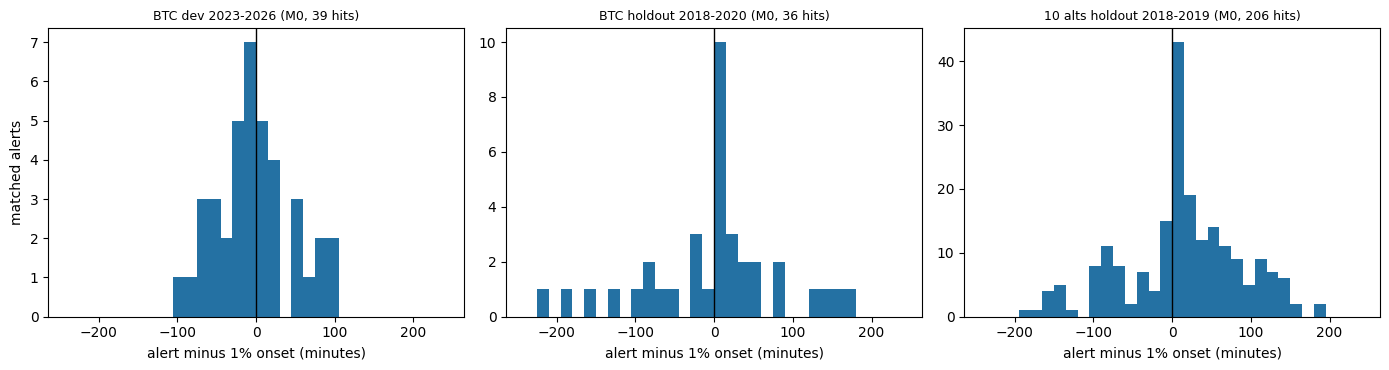

In [6]:
def lead_rows(sample, mname, ev, a, grid=None, closes=None):
    m = match_events(ev, np.sort(np.asarray(a, np.int64)))
    if not len(m):
        return []
    m = m.merge(ev[['event_id', 'onset_1pct_utc', 'peak_close', 'breach_close']], on='event_id')
    al = m.alarm_utc.astype('int64').to_numpy(); mins = (al - m.onset_1pct_utc.astype('int64').to_numpy()) / NS
    dec = np.full(len(m), np.nan); share = np.full(len(m), np.nan)
    if grid is not None:
        c_al = at(al, grid, closes); dec = 1 - c_al / m.peak_close.to_numpy(); share = dec / (1 - m.breach_close.to_numpy() / m.peak_close.to_numpy())
    return [dict(sample=sample, method=mname, event_id=int(e), pre_onset=bool(p), minutes_from_onset=float(x), decline_at_alert=float(dd), share_of_drop_realised=float(sh))
            for e, p, x, dd, sh in zip(m.event_id, m.pre1pct, mins, dec, share)]


LR = []
for mname in METHODS:
    a16 = pd.to_datetime(pd.read_csv(M16 / f'alarms_{mname}_{DNAME}.csv').alarm_utc, utc=True).astype('int64').to_numpy()
    LR += lead_rows('BTC dev 2023-2026', mname, EV, a16, T, close)
    for sym, d in ALT.items():
        LR += lead_rows('10 alts holdout 2018-2019', mname, d['ev'], d['A'][f'{mname}|{ALT_DEF}'])
LR += lead_rows('BTC holdout 2018-2020', 'M0_VF_logit', hev, h_al, HT, Hc)
LT = pd.DataFrame(LR); LT.to_csv(OUT / '3_lead_times.csv', index=False)


def summ(g):
    med = lambda x: float(x.median()) if x.notna().any() else np.nan
    pre = g[g.pre_onset]; post = g[~g.pre_onset]
    return dict(hits=len(g), pre_hits=len(pre), median_min_before_onset_pre=-med(pre.minutes_from_onset),
                share_pre_within_15min=float((pre.minutes_from_onset >= -15).mean()) if len(pre) else np.nan,
                share_pre_within_60min=float((pre.minutes_from_onset >= -60).mean()) if len(pre) else np.nan,
                median_decline_at_pre_alert_pct=100 * med(pre.decline_at_alert),
                median_min_after_onset_post=med(post.minutes_from_onset),
                median_share_of_drop_realised_post=med(post.share_of_drop_realised))


LS = pd.DataFrame([dict(sample=k[0], method=k[1], **summ(g)) for k, g in LT.groupby(['sample', 'method'])]); LS.to_csv(OUT / '3_lead_time_summary.csv', index=False); display(LS.round(3))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=False)
for a_, smp in zip(ax, ['BTC dev 2023-2026', 'BTC holdout 2018-2020', '10 alts holdout 2018-2019']):
    g = LT[(LT['sample'] == smp) & (LT.method == 'M0_VF_logit')]
    a_.hist(g.minutes_from_onset.clip(-240, 240), bins=np.arange(-240, 250, 15), color='#2471a3')
    a_.axvline(0, color='k', lw=1); a_.set_title(f'{smp} (M0, {len(g)} hits)', fontsize=9); a_.set_xlabel('alert minus 1% onset (minutes)')
ax[0].set_ylabel('matched alerts'); plt.tight_layout(); plt.savefig(OUT / '3_lead_times.png', dpi=140); plt.show()

## D. Use of the frozen thresholds and budgets in other periods

In [7]:
cap_rows = []
for mname in METHODS + ['M2_VPIN']:
    s = S.get(mname, S_VPIN); th = FROZEN16['configs'][f'{mname}|{DNAME}']['threshold_2022']
    r22 = float(np.mean(s[CAL & np.isfinite(s)] >= th)); rdv = float(np.mean(s[EVM & np.isfinite(s)] >= th))
    n = FROZEN16['configs'][f'{mname}|{DNAME}']['dev_alerts']; capn = capacity(EVAL_START, EVAL_END, 240, 20)
    cap_rows.append(dict(sample='BTC dev 2023-2026', coin='BTCUSDT', method=mname, alerts=n, capacity=capn, utilization=n / capn,
                         candidate_rate_2022=r22, candidate_rate_eval=rdv, candidate_rate_ratio=rdv / r22 if r22 else np.nan))
capn = capacity(*H11, 240, 20)
cap_rows.append(dict(sample='BTC holdout 2018-2020', coin='BTCUSDT', method='M0_VF_logit', alerts=len(h_al), capacity=capn, utilization=len(h_al) / capn))
for sym, d in ALT.items():
    capn = capacity(d['meta']['eval_start'], H17_END, 240, 20)
    for k, a in d['A'].items():
        mname, dn = k.split('|')
        if dn == ALT_DEF:
            cap_rows.append(dict(sample='10 alts holdout 2018-2019', coin=sym, method=mname, alerts=len(a), capacity=capn, utilization=len(a) / capn))
CU = pd.DataFrame(cap_rows); CU.to_csv(OUT / '4_capacity_use.csv', index=False)
display(CU[CU['sample'] != '10 alts holdout 2018-2019'].round(3))
display(CU[CU['sample'] == '10 alts holdout 2018-2019'].groupby('method').utilization.describe()[['min', '25%', '50%', 'max']].round(2))
miss = json.loads((HOLD11 / 'HOLDOUT_RESULTS.json').read_text()).get('H3', {})
print('notebook-11 H3 (stored): share of missed events with no budget room =', miss.get('share_of_misses_with_no_room'))

,sample,coin,method,alerts,capacity,utilization,candidate_rate_2022,candidate_rate_eval,candidate_rate_ratio
0,BTC dev 2023-2026,BTCUSDT,M0_VF_logit,800,800,1.00,0.061,0.053,0.872
1,BTC dev 2023-2026,BTCUSDT,M1_vol_threshold,800,800,1.00,0.061,0.053,0.871
2,BTC dev 2023-2026,BTCUSDT,M3_GBM_rich,768,800,0.96,0.257,0.089,0.346
3,BTC dev 2023-2026,BTCUSDT,M2_VPIN,800,800,1.00,0.704,0.945,1.342
4,BTC holdout 2018-2020,BTCUSDT,M0_VF_logit,713,720,0.99,NaN,NaN,NaN


,min,25%,50%,max
method,,,,
M0_VF_logit,0.95,0.96,0.97,0.99
M1_vol_threshold,0.92,0.95,0.96,0.99
M2_VPIN,0.95,0.95,1.00,1.00
M3_GBM_rich,0.23,0.63,0.92,1.00


notebook-11 H3 (stored): share of missed events with no budget room = 0.6319018404907976


## Summary

In [8]:
summary = dict(spec_sha256=SPEC_SHA, status='exploratory (budget sweep, dev) and post hoc descriptive (holdout files); no holdout hypothesis re-tested',
               budget_sweep=BU[['method', 'budget_per_year', 'dev_alerts', 'pre', 'post', 'pre_excess_events', 'post_excess_events', 'p_pre_regime', 'p_post_regime',
                                'pre_excess_per_100_alerts', 'post_excess_per_100_alerts', 'post_share_of_excess']].to_dict('records'),
               contagion_share_btc_down_1pct=AC[AC.btc_down_threshold == LED_DD].pivot(index='category', columns='method', values='share_btc_down').round(4).to_dict(),
               btc_led_events=LED.to_dict('records'), lead_time=LS.to_dict('records'),
               capacity_alts=CU[CU['sample'] == '10 alts holdout 2018-2019'].groupby('method').utilization.describe()[['min', '50%', 'max']].round(3).to_dict('index'),
               btc_holdout_misses_with_no_room=miss.get('share_of_misses_with_no_room'))
(OUT / 'CONTAGION_CAPACITY_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
print('saved', OUT / 'CONTAGION_CAPACITY_SUMMARY.json')

saved /content/drive/MyDrive/btc_lead_cost_results_77months_spot/contagion_capacity_leadtime_v1/CONTAGION_CAPACITY_SUMMARY.json


## Interpretation
- A. If the share of pre-onset hits with BTC already at least 1% down is much higher than at arbitrary minutes and at false alerts, and pre-onset hits concentrate in events where BTC fell first, I read the altcoin early warnings as detection of BTC declines; a share close to the baseline rules this explanation out. Because the analysis is post hoc, I treat its p-values as indicative only.
- B. If only the in-progress excess grows with the budget while pre-onset warning stays flat, more capacity adds detection, not prediction; if both grow, capacity is the bottleneck for pre-onset warning.
- C. If most pre-onset hits fall within 15 minutes before onset, many early warnings are detection of the moment the decline begins.
- D. If the same thresholds leave most of the budget unused (under-alerting) or the candidate rate shifts strongly across periods and coins, I report this as a practical risk for capacity-constrained systems.